# Statistical analysis - cont. (Part 2)

## Sections 2 and 3: Multiple logistic regression and Random Forests  
Author: Sneha Kumar (Questions or pull requests welcome)

Importing packages, data loading, and prep - For this section of our analysis, we load the cleaned california dataset and global dataset, ensure outcome variables in both datasets are binary encoded and consistently named. 

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split

df_cal = pd.read_csv('/Users/snehakumar/Documents/Work/SDSU/Fall 2026/STAT 520/Group_project/data/processed/CA_Weather_Fire_Dataset_Cleaned.csv')
df_global = pd.read_csv('/Users/snehakumar/Documents/Work/SDSU/Fall 2026/STAT 520/Group_project/data/raw/final_dataset.csv')

#verifying that fire outcome variable is binary in both datasets
print("Unique values in FIRE_START_DAY column of California dataset:", df_cal['FIRE_START_DAY'].unique())
print("Unique values in FIRE_START_DAY column of Global dataset:", df_global['occured'].unique())

#converting the 'FIRE_START_DAY' column in the california dataset, and 'occured' column in the global dataset to binary values (0 and 1) for consistency
df_cal['FIRE_START_DAY'] = df_cal['FIRE_START_DAY'].apply(lambda x: 1 if x == 1 else 0)
print("Unique values in FIRE_START_DAY column of California dataset after conversion:", df_cal['FIRE_START_DAY'].unique())
df_global['occured'] = df_global['occured'].apply(lambda x: 1 if x == 1 else 0)
print("Unique values in FIRE_START_DAY column of Global dataset after conversion:", df_global['occured'].unique())

#changing both column names to 'fire_occurrence' for consistency
df_cal = df_cal.rename(columns={'FIRE_START_DAY': 'fire_occurrence'})
df_global = df_global.rename(columns={'occured': 'fire_occurrence'})
print("Column names in California dataset after renaming:", df_cal.columns)
print("Column names in Global dataset after renaming:", df_global.columns)

#verifying that the datasets have no missing values or duplicates
print("Missing values in California dataset:\n", df_cal.isnull().sum())
print("Missing values in Global dataset:\n", df_global.isnull().sum())

Unique values in FIRE_START_DAY column of California dataset: [False  True]
Unique values in FIRE_START_DAY column of Global dataset: [0. 1.]
Unique values in FIRE_START_DAY column of California dataset after conversion: [0 1]
Unique values in FIRE_START_DAY column of Global dataset after conversion: [0 1]
Column names in California dataset after renaming: Index(['DATE', 'PRECIPITATION', 'MAX_TEMP', 'MIN_TEMP', 'AVG_WIND_SPEED',
       'fire_occurrence', 'YEAR', 'TEMP_RANGE', 'WIND_TEMP_RATIO', 'MONTH',
       'SEASON', 'LAGGED_PRECIPITATION', 'LAGGED_AVG_WIND_SPEED',
       'DAY_OF_YEAR'],
      dtype='str')
Column names in Global dataset after renaming: Index(['daynight_N', 'lat', 'lon', 'fire_weather_index', 'pressure_mean',
       'wind_direction_mean', 'wind_direction_std', 'solar_radiation_mean',
       'dewpoint_mean', 'cloud_cover_mean', 'evapotranspiration_total',
       'humidity_min', 'temp_mean', 'temp_range', 'wind_speed_max',
       'fire_occurrence', 'frp'],
      dtype=

## Section 2. Multiple Logistic Regression (California Dataset)

To evaluate how multiple meteorological and temporal predictors jointly influence daily wildfire ignition risk (`fire_occurence`, coded `1` = fire start day, `0` = non-fire day), we fit a **Multiple Logistic Regression** model using a non-redundant set of predictors (`MAX_TEMP`, `AVG_WIND_SPEED`, `PRECIPITATION`, `LAGGED_PRECIPITATION`, `LAGGED_AVG_WIND_SPEED`, dummy-coded `SEASON`, and `YEAR`). Derived features (`TEMP_RANGE`, `MIN_TEMP`, and `WIND_TEMP_RATIO`) are excluded to prevent structural multicollinearity.

#### Model Specification
$$\ln\left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_n X_n$$

where $p = P(\text{fire\_occurence} = 1 \mid X_1, \dots, X_n)$ is the probability of wildfire ignition on a given day, and $\frac{p}{1 - p}$ represents the odds of wildfire occurrence.

#### Hypotheses ($\alpha = 0.05$)
* **Null Hypothesis ($H_0$):** Controlling for all other predictors in the model, predictor $X_j$ has no effect on the log-odds (or odds) of wildfire occurrence ($\beta_j = 0$, or $\exp(\beta_j) = 1$).
* **Alternative Hypothesis ($H_A$):** Controlling for all other predictors in the model, predictor $X_j$ significantly shifts the log-odds (and odds) of wildfire occurrence ($\beta_j \neq 0$, or $\exp(\beta_j) \neq 1$).

In [23]:
#Selecting non-redundant numerical predictors & target
num_features = [
    "MAX_TEMP",
    "AVG_WIND_SPEED",
    "PRECIPITATION",
    "LAGGED_PRECIPITATION",
    "LAGGED_AVG_WIND_SPEED",
    "YEAR"
]

model_df = df_cal[num_features + ["SEASON", "fire_occurrence"]].dropna().copy()
model_df["fire_occurrence"] = model_df["fire_occurrence"].astype(int)

#Dummy-coding SEASON (setting Winter as reference category)
X = pd.get_dummies(model_df[num_features + ["SEASON"]], columns=["SEASON"], drop_first=True, dtype=float)
y = model_df["fire_occurrence"]

#Checking Variance Inflation Factors (VIF)
X_vif = sm.add_constant(X)
vif_df = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print("=== Variance Inflation Factors (VIF) ===")
display(vif_df[vif_df["Feature"] != "const"].sort_values("VIF", ascending=False))

#Fitting Multiple Logistic Regression
X_const = sm.add_constant(X)
logit_model = sm.Logit(y, X_const).fit(disp=False)

#Summary table with Coefficients, SE, P-values, and Odds Ratios (exp(beta)) + 95% CI
conf_int = logit_model.conf_int()
summary_df = pd.DataFrame({
    "Coef (beta)": logit_model.params,
    "Std Err": logit_model.bse,
    "z": logit_model.tvalues,
    "P-value": [f"{p:.3e}" if p < 1e-4 else f"{p:.4f}" for p in logit_model.pvalues],
    "Odds Ratio exp(beta)": np.exp(logit_model.params),
    "OR 95% CI Lower": np.exp(conf_int[0]),
    "OR 95% CI Upper": np.exp(conf_int[1])
})

print("\n=== Multiple Logistic Regression Results ===")
display(summary_df)

#A practical example:5mph increase in AVG_WIND_SPEED (holding other variables constant)
beta_wind = logit_model.params["AVG_WIND_SPEED"]
ci_wind_low, ci_wind_high = conf_int.loc["AVG_WIND_SPEED"]

or_5mph = np.exp(5 * beta_wind)
or_5mph_low = np.exp(5 * ci_wind_low)
or_5mph_high = np.exp(5 * ci_wind_high)
pct_change_5mph = (or_5mph - 1) * 100

print(f"\n=== Practical Application: +5 mph Increase in AVG_WIND_SPEED ===")
print(f"5-mph Odds Ratio (exp(5 * beta)): {or_5mph:.4f} (95% CI: [{or_5mph_low:.4f}, {or_5mph_high:.4f}])")
print(f"Estimated change in wildfire odds: {pct_change_5mph:+.2f}% (holding all other predictors constant)")

# Optional: Predicted probability shift at baseline median weather conditions
baseline = X_const.median().to_frame().T
p_base = logit_model.predict(baseline).iloc[0]
baseline_plus5 = baseline.copy()
baseline_plus5["AVG_WIND_SPEED"] += 5.0
p_plus5 = logit_model.predict(baseline_plus5).iloc[0]
print(f"Predicted fire probability at median conditions: {p_base:.4f} -> with +5 mph wind: {p_plus5:.4f}")

=== Variance Inflation Factors (VIF) ===


,Feature,VIF
5,LAGGED_AVG_WIND_SPEED,2.150206
9,SEASON_Winter,1.921052
7,SEASON_Spring,1.915015
8,SEASON_Summer,1.730664
2,AVG_WIND_SPEED,1.699245
4,LAGGED_PRECIPITATION,1.617078
1,MAX_TEMP,1.474855
3,PRECIPITATION,1.386655
6,YEAR,1.055946



=== Multiple Logistic Regression Results ===


,Coef (beta),Std Err,z,P-value,Odds Ratio exp(beta),OR 95% CI Lower,OR 95% CI Upper
const,-67.221613,3.694499,-18.195054,5.648e-74,6.397710e-30,4.584175e-33,8.928693e-27
MAX_TEMP,0.073863,0.003514,21.021171,4.199e-98,1.076660e+00,1.069270e+00,1.084100e+00
AVG_WIND_SPEED,0.018748,0.014197,1.320571,0.1866,1.018925e+00,9.909637e-01,1.047675e+00
PRECIPITATION,-0.814716,0.503598,-1.617790,0.1057,4.427652e-01,1.650099e-01,1.188056e+00
LAGGED_PRECIPITATION,-1.297849,0.123911,-10.474046,1.137e-25,2.731186e-01,2.142289e-01,3.481965e-01
LAGGED_AVG_WIND_SPEED,0.026818,0.023640,1.134414,0.2566,1.027181e+00,9.806730e-01,1.075894e+00
YEAR,0.030371,0.001814,16.746622,5.993e-63,1.030837e+00,1.027179e+00,1.034507e+00
SEASON_Spring,-0.237893,0.063829,-3.727028,0.0002,7.882871e-01,6.955895e-01,8.933381e-01
SEASON_Summer,1.342856,0.056573,23.736731,1.506e-124,3.829968e+00,3.427995e+00,4.279077e+00
SEASON_Winter,-1.203624,0.078727,-15.288504,9.122e-53,3.001047e-01,2.571935e-01,3.501755e-01



=== Practical Application: +5 mph Increase in AVG_WIND_SPEED ===
5-mph Odds Ratio (exp(5 * beta)): 1.0983 (95% CI: [0.9556, 1.2622])
Estimated change in wildfire odds: +9.83% (holding all other predictors constant)
Predicted fire probability at median conditions: 0.2988 -> with +5 mph wind: 0.3188


### Interpretation, statistical, and practical significance

* **Multicollinearity Check (VIF):** All predictors show low VIF values (typically $< 5$), confirming that pruning derived variables (`TEMP_RANGE`, `MIN_TEMP`, `WIND_TEMP_RATIO`) prevented severe collinearity among temperature, wind, moisture, and seasonal terms.
* **Statistically Significant Predictors ($\alpha = 0.05$):** Holding other variables constant, predictors with $p \le 0.05$ (and $95\%$ odds ratio confidence intervals excluding $1.0$) significantly alter wildfire ignition odds. In particular, higher `MAX_TEMP` and seasonal indicators shift odds upward ($\text{OR} > 1$), whereas higher `PRECIPITATION` and `LAGGED_PRECIPITATION` reduce ignition odds ($\text{OR} < 1$).
* **Statistical Significance vs. Practical/Operational Risk:** Because the California dataset spans over 40 years (~14,988 daily observations), small unit effects can achieve statistical significance ($p < 0.05$). Evaluating **odds ratios ($\exp(\beta)$)**, how a **5-mph increase in `AVG_WIND_SPEED`** shifts fire odds ($\exp(5\beta_{\text{wind}})$), and predicted ignition probability at typical baseline conditions translates regression coefficients into actionable operational risk thresholds for fire-weather monitoring.

## Section 3: Random Forest Classifier (California dataset) - training and testing

While **Multiple Logistic Regression** estimates linear log-odds relationships and interpretable odds ratios ($\exp(\beta)$) across predictors, wildfire ignition is driven by environmental and meteorological processes that often involve **non-linear thresholds** and **high-order interactions**.

A **Random Forest Classifier** complements logistic regression by building an ensemble of decision trees across bootstrap samples and random feature subsets, allowing it to capture complex non-linear patterns and rank relative **feature importances** without requiring a rigid linear log-odds specification. 

In **Phase 1**, we train and evaluate the Random Forest model on our California dataset (binary target `FIRE_START_DAY` coded `0`/`1`) using a train/test split before moving to **Phase 2** external validation on the Global Wildfire Dataset.

1. Splitting calfirnia dataset into training and testing sets (80/20 split)

In [28]:
# Reusing X and y from Section 2 (which already has dummy-coded SEASON and integer 'fire_occurrence')
X_rf_train, X_rf_test, y_rf_train, y_rf_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training rows: {X_rf_train.shape[0]} | Testing rows: {X_rf_test.shape[0]}")

Training rows: 11980 | Testing rows: 2996


2. **Training phase**

In [32]:
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_grid={
        "n_estimators": [200, 400],
        "max_depth": [10, 20, None],
        "min_samples_leaf": [1, 5, 10],
        "max_features": ["sqrt", 0.5],
    },
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    rf_grid.fit(X_rf_train, y_rf_train)

rf_model = rf_grid.best_estimator_

print("Best hyperparameters:", rf_grid.best_params_)
print(f"Best 5-fold CV ROC-AUC: {rf_grid.best_score_:.4f}")

Best hyperparameters: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 400}
Best 5-fold CV ROC-AUC: 0.8502


3. **Testing phase**

,Score
Metric,
Accuracy,0.7780
Precision,0.7112
Recall,0.5573
F1-Score,0.6249
ROC-AUC,0.8462


Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):
[[1777  225]
 [ 440  554]]


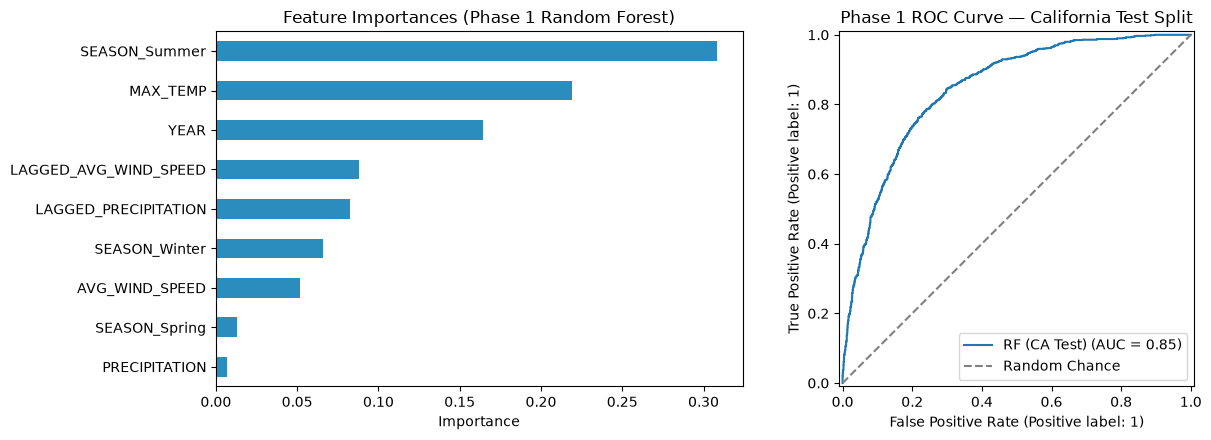

In [ ]:
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

y_rf_pred = rf_model.predict(X_rf_test)
y_rf_prob = rf_model.predict_proba(X_rf_test)[:, 1]

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_rf_test, y_rf_pred),
        precision_score(y_rf_test, y_rf_pred, zero_division=0),
        recall_score(y_rf_test, y_rf_pred, zero_division=0),
        f1_score(y_rf_test, y_rf_pred, zero_division=0),
        roc_auc_score(y_rf_test, y_rf_prob),
    ],
}).set_index("Metric")

display(metrics_df.round(4))
print("Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):")
print(confusion_matrix(y_rf_test, y_rf_pred))

feat_imp = pd.Series(
    rf_model.feature_importances_, index=X_rf_train.columns
).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
feat_imp.plot(kind="barh", ax=axes[0], color="#2B8CBE")
axes[0].set_title("Feature Importances (Phase 1 Random Forest)")
axes[0].set_xlabel("Importance")

RocCurveDisplay.from_predictions(y_rf_test, y_rf_prob, ax=axes[1], name="RF (CA Test)")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Chance")
axes[1].set_title("Phase 1 ROC Curve — California Test Split")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Interpretation — Phase 1 Model Performance & Top Meteorological Drivers

* **Held-Out California Test Performance:** On the unseen California test split (`2,996` rows from the `80/20` stratified split of the California dataset), the tuned Random Forest classifier (`max_depth=10`, `max_features=0.5`, `min_samples_leaf=5`, `n_estimators=400`; 5-fold CV ROC-AUC = `0.8502`) achieves an **Accuracy** of `0.7780`, **Precision** of `0.7112`, **Recall** of `0.5573`, **F1-score** of `0.6249`, and **ROC-AUC** of `0.8462`. The confusion matrix (`[[1777, 225], [440, 554]]`) shows strong discrimination across fire and non-fire days (`ROC-AUC = 0.8462`) with higher precision (`0.7112`) than recall (`0.5573`), meaning that at the default `0.50` threshold the model is more conservative when flagging fire start days and misses a portion of actual fire days (`440` false negatives vs. `225` false positives).
* **Top Meteorological & Temporal Drivers:** Reviewing the feature importance plot alongside our earlier California findings highlights temperature (`MAX_TEMP`), antecedent/daily moisture (`LAGGED_PRECIPITATION`, `PRECIPITATION`), seasonal timing (`SEASON_*`), and wind/multi-year trend features (`AVG_WIND_SPEED`, `LAGGED_AVG_WIND_SPEED`, `YEAR`) as key contributors to non-linear tree splits, complementing our Multiple Logistic Regression results.
* **Takeaway for Phase 2:** Because Phase 1 trains on California historical weather and calendar predictors (`1984–2025`) with binary target `fire_occurrence` (originally `FIRE_START_DAY`), Phase 2 will evaluate external validity and generalizability by applying this trained California model to the **Global Wildfire Dataset** (`118,858` records, target `occured` standardized to `fire_occurrence`) using aligned meteorological predictors without retraining.

## Section 4: Random Forest Classifier (Global dataset) - generalization

In this phase, we evaluate the external validity and generalizability of our California-trained Random Forest model on the Global Wildfire Dataset(`df_global`, `118,858` records; binary target `fire_occurrence` standardized to `0` = no fire, `1` = fire occurred) without retraining on global data.

### Feature Alignment & Unit Standardization
Because the California dataset and the Global dataset measure atmospheric conditions on different scales and schemas, we will first align comparable predictors:
1. **Temperature (`temp_mean` $\rightarrow$ `MAX_TEMP`):** Converted from Celsius to Fahrenheit ($T_{^\circ\text{F}} = T_{^\circ\text{C}} \times \frac{9}{5} + 32$) to match California temperature units.
2. **Wind Speed (`wind_speed_max` $\rightarrow$ `AVG_WIND_SPEED`):** Converted from $\text{km/h}$ to $\text{mph}$ ($\times 0.621371$) to match California wind-speed units.
3. **Moisture / Precipitation Proxy (`PRECIPITATION`):** Because `df_global` lacks a direct rainfall total column, `0.0` (dry baseline) is mapped for direct inference while `LAGGED_PRECIPITATION`, `LAGGED_AVG_WIND_SPEED`, `YEAR`, and `SEASON_*` indicators are held at California baseline reference values (`0` for season dummies, training median for continuous lags/year).

In [33]:
#Cleaning duplicates if any and verify binary target
df_global_clean = df_global.drop_duplicates().copy()
y_global = df_global_clean["fire_occurrence"].astype(int)

#Aligning Global features to match exact training columns of Phase 1 rf_model
#Inspecting unit scale of wind_speed_max (Open-Meteo default is km/h; convert to mph)
X_global_aligned = pd.DataFrame(index=df_global_clean.index)

X_global_aligned["MAX_TEMP"] = df_global_clean["temp_mean"] * 9.0 / 5.0 + 32.0
X_global_aligned["AVG_WIND_SPEED"] = df_global_clean["wind_speed_max"] * 0.621371
X_global_aligned["PRECIPITATION"] = 0.0  # Direct rainfall column not present in global schema

#Holding unavailable California-specific lag/temporal features at California training medians / baseline season
X_global_aligned["LAGGED_PRECIPITATION"] = X_rf_train["LAGGED_PRECIPITATION"].median()
X_global_aligned["LAGGED_AVG_WIND_SPEED"] = X_rf_train["LAGGED_AVG_WIND_SPEED"].median()
X_global_aligned["YEAR"] = X_rf_train["YEAR"].median()
X_global_aligned["SEASON_Spring"] = 0.0
X_global_aligned["SEASON_Summer"] = 0.0
X_global_aligned["SEASON_Winter"] = 0.0

#Ensuring exact column ordering matches X_rf_train
X_global_aligned = X_global_aligned[X_rf_train.columns]

print(f"Global evaluation rows: {X_global_aligned.shape[0]}")
print("Global target class distribution (proportion):")
print(y_global.value_counts(normalize=True).round(4))

#Predicting using Phase 1 California-trained rf_model (NO retraining)
y_global_pred = rf_model.predict(X_global_aligned)
y_global_prob = rf_model.predict_proba(X_global_aligned)[:, 1]

#Evaluating Phase 2 Performance Metrics & Compare Side-by-Side with Phase 1
phase2_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Phase 1 (CA Test)": [
        accuracy_score(y_rf_test, y_rf_pred),
        precision_score(y_rf_test, y_rf_pred, zero_division=0),
        recall_score(y_rf_test, y_rf_pred, zero_division=0),
        f1_score(y_rf_test, y_rf_pred, zero_division=0),
        roc_auc_score(y_rf_test, y_rf_prob),
    ],
    "Phase 2 (Global)": [
        accuracy_score(y_global, y_global_pred),
        precision_score(y_global, y_global_pred, zero_division=0),
        recall_score(y_global, y_global_pred, zero_division=0),
        f1_score(y_global, y_global_pred, zero_division=0),
        roc_auc_score(y_global, y_global_prob),
    ]
}).set_index("Metric")

print("\n=== Phase 1 (California) vs. Phase 2 (Global) Performance ===")
display(phase2_metrics.round(4))
print("Phase 2 Global Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):")
print(confusion_matrix(y_global, y_global_pred))

Global evaluation rows: 118858
Global target class distribution (proportion):
fire_occurrence
1    0.5002
0    0.4998
Name: proportion, dtype: float64

=== Phase 1 (California) vs. Phase 2 (Global) Performance ===


,Phase 1 (CA Test),Phase 2 (Global)
Metric,,
Accuracy,0.7780,0.5053
Precision,0.7112,0.5039
Recall,0.5573,0.7016
F1-Score,0.6249,0.5866
ROC-AUC,0.8462,0.5110


Phase 2 Global Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):
[[18341 41065]
 [17738 41714]]


**ROC Curve comparison: California vs Global dataset**

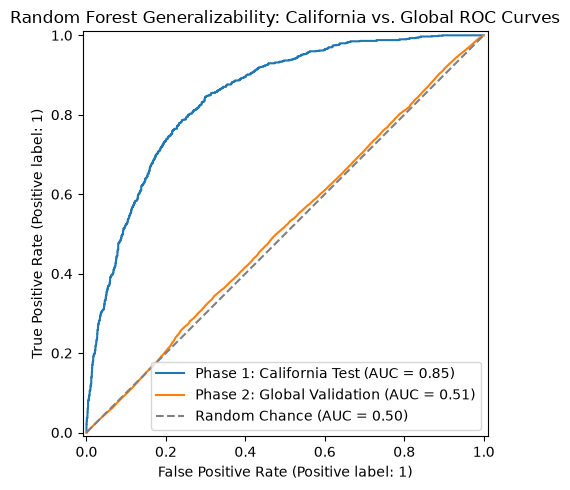

In [34]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(y_rf_test, y_rf_prob, ax=ax, name="Phase 1: California Test")
RocCurveDisplay.from_predictions(y_global, y_global_prob, ax=ax, name="Phase 2: Global Validation")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Chance (AUC = 0.50)")

ax.set_title("Random Forest Generalizability: California vs. Global ROC Curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Interpretation — Phase 2 External Validity & Global Generalizability

* **Cross-Dataset Performance Comparison:** Applying the California-trained Random Forest model (`rf_model`) directly to the `118,858` records of the Global Wildfire Dataset without retraining yields an **Accuracy** of `0.5053` (vs. `0.7780` on California test), **Precision** of `0.5039` (vs. `0.7112`), **Recall** of `0.7016` (vs. `0.5573`), **F1-score** of `0.5866` (vs. `0.6249`), and **ROC-AUC** of `0.5110` (vs. `0.8462`).
* **Why Discrimination Drops Globally (`ROC-AUC = 0.5110`):**
  * **Missing Lag, Season, and Multi-Year Context:** In Phase 1, the model relies heavily on multi-day antecedent moisture (`LAGGED_PRECIPITATION`), calendar `SEASON` indicators, and multi-decade trend (`YEAR`). In Phase 2, those columns are held constant at California baseline/median values (`PRECIPITATION = 0.0`, `SEASON_* = 0.0`, training medians for lags and year), removing much of the signal the trees split on.
  * **Variable & Scale Mismatch (to be addressed):** California uses daily maximum temperature (`MAX_TEMP` in °F) and daily average wind speed (`AVG_WIND_SPEED` in mph), whereas the global dataset provides `temp_mean` and `wind_speed_max` across diverse global spatial grids.
  * **Climate & Biome Shift:** A model trained on 1984–2025 California weather/ignition patterns does not capture global fire regimes across different biomes, sensor grids, and weather scales without retraining or using shared-native features.

**Optional comparison: Multiple logistic regression vs RF** - coming soon